# 01 – Data cleaning and preparation

Goal: build the modelling table with 8 inputs, the target `species` (top 6 species), `site` (used only to group the splits) and `fold`.
No scaling or encoding here: that will go in the Pipeline later.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold

## 1. Load and inspect

* `1_stream_information.txt`: one row per site (`Code_ID`) with the environmental variables
* `2_fish_information.txt`: one row per fish with species, length and mass

The two files are joined on `Code_ID`.

In [2]:
streams = pd.read_csv("../data/1_stream_information.txt", sep="\t")
fish = pd.read_csv("../data/2_fish_information.txt", sep="\t")

print("streams:", streams.shape)
print("fish:", fish.shape)

streams: (118, 17)
fish: (12288, 9)


In [3]:
print(streams.dtypes)
streams.head()

Code_ID                  int64
Stream                     str
Location                   str
Lat_degree             float64
Long_degree            float64
Source                     str
Day                      int64
Month                    int64
Year                     int64
Fish_number              int64
SA_m2                  float64
TP_mg.l                float64
TN_mg.l                float64
Temp_degree_celcius    float64
Prec_mm                  int64
Alt_m                  float64
IMPRESS                float64
dtype: object


,Code_ID,Stream,Location,Lat_degree,Long_degree,Source,Day,Month,Year,Fish_number,SA_m2,TP_mg.l,TN_mg.l,Temp_degree_celcius,Prec_mm,Alt_m,IMPRESS
0,1,Ebro,Miranda de Ebro,42.687282,-2.954187,CHE,18,10,2007,74,698.0,0.10,8.38,12.5,727,454.68,2.00
1,2,Arga,Funes,42.301003,-1.789143,CHE,8,7,2007,143,415.0,0.24,10.93,13.6,576,279.10,10.50
2,3,Aragon,Caparroso,42.344712,-1.650659,CHE,27,8,2007,70,575.0,0.10,8.35,13.4,625,300.01,10.65
3,4,Martin,Hijar,41.173897,-0.456685,CHE,25,10,2007,68,358.0,0.13,13.10,14.6,371,294.61,10.75
4,5,Guadalope,Alcaniz,40.932767,-0.196697,CHE,24,10,2006,54,887.0,0.11,10.33,14.3,431,383.92,10.25


In [4]:
print(fish.dtypes)
fish.head()

Code_ID              int64
Stream                 str
Location               str
Family                 str
Genus                  str
Species                str
Scientific_name        str
Length_mm            int64
Mass_g             float64
dtype: object


,Code_ID,Stream,Location,Family,Genus,Species,Scientific_name,Length_mm,Mass_g
0,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,442,1700.0
1,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,405,1220.0
2,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,373,1040.0
3,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,199,139.9
4,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,225,133.0


**Column mapping**

| New name | Raw column | Table |
|---|---|---|
| length_mm | Length_mm | fish |
| mass_g | Mass_g | fish |
| temperature_c | Temp_degree_celcius | streams |
| precipitation_mm | Prec_mm | streams |
| altitude_m | Alt_m | streams |
| total_phosphorus_mg_l | TP_mg.l | streams |
| nitrates_mg_l | TN_mg.l | streams |
| impress | IMPRESS | streams |
| species (target) | Scientific_name | fish |
| site (group) | Code_ID | both |

Choices:
* Species: `Scientific_name` (genus + species), because the `Species` column is only the second part of the name.
* Site: `Code_ID`, the unique ID of each sampling point. `Location` is not unique (Code_ID 5 and 87 are both "Guadalope – Alcaniz" but at different coordinates).
* `TN_mg.l` is described as "total nitrates" in the data dictionary (it could also mean total nitrogen).

In [5]:
# Code_ID 5 and 87 share the same Stream and Location but are different points
streams[streams.duplicated(["Stream", "Location"], keep=False)][["Code_ID", "Stream", "Location", "Lat_degree", "Long_degree", "Alt_m"]]

,Code_ID,Stream,Location,Lat_degree,Long_degree,Alt_m
4,5,Guadalope,Alcaniz,40.932767,-0.196697,383.92
86,87,Guadalope,Alcaniz,41.073193,-0.092226,299.72


In [6]:
env_cols = ["Code_ID", "Temp_degree_celcius", "Prec_mm", "Alt_m", "TP_mg.l", "TN_mg.l", "IMPRESS"]
df = fish.merge(streams[env_cols], on="Code_ID", how="left")

df = df.rename(columns={
    "Length_mm": "length_mm",
    "Mass_g": "mass_g",
    "Temp_degree_celcius": "temperature_c",
    "Prec_mm": "precipitation_mm",
    "Alt_m": "altitude_m",
    "TP_mg.l": "total_phosphorus_mg_l",
    "TN_mg.l": "nitrates_mg_l",
    "IMPRESS": "impress",
    "Scientific_name": "species",
    "Code_ID": "site",
})

features = ["length_mm", "mass_g", "temperature_c", "precipitation_mm", "altitude_m",
            "total_phosphorus_mg_l", "nitrates_mg_l", "impress"]

df = df[features + ["species", "site", "Location"]]
print(df.shape)
df.head()

(12288, 11)


,length_mm,mass_g,temperature_c,precipitation_mm,altitude_m,total_phosphorus_mg_l,nitrates_mg_l,impress,species,site,Location
0,442,1700.0,12.5,727,454.68,0.1,8.38,2.0,Cyprinus carpio,1,Miranda de Ebro
1,405,1220.0,12.5,727,454.68,0.1,8.38,2.0,Cyprinus carpio,1,Miranda de Ebro
2,373,1040.0,12.5,727,454.68,0.1,8.38,2.0,Cyprinus carpio,1,Miranda de Ebro
3,199,139.9,12.5,727,454.68,0.1,8.38,2.0,Cyprinus carpio,1,Miranda de Ebro
4,225,133.0,12.5,727,454.68,0.1,8.38,2.0,Luciobarbus graellsii,1,Miranda de Ebro


In [7]:
# Cleaning log: one row per step
log = []
log.append(["load_and_merge", len(fish), len(df), "fish table joined to stream table on Code_ID"])

## 2. Quality audit

In [8]:
# Missing values
missing = pd.DataFrame({"count": df.isna().sum(), "percent": df.isna().mean() * 100})
missing

,count,percent
length_mm,0,0.0
mass_g,0,0.0
temperature_c,0,0.0
precipitation_mm,0,0.0
altitude_m,0,0.0
total_phosphorus_mg_l,0,0.0
nitrates_mg_l,0,0.0
impress,0,0.0
species,0,0.0
site,0,0.0


In [9]:
# Duplicates
print("Exact duplicate rows:", df.duplicated().sum())

# Number of fish rows per site vs Fish_number in the stream file
rows_per_site = fish.groupby("Code_ID").size()
fish_number = streams.set_index("Code_ID")["Fish_number"]
print("Sites where rows != Fish_number:", (rows_per_site != fish_number).sum())

Exact duplicate rows: 883
Sites where rows != Fish_number: 0


In [10]:
# Impossible values
print("length_mm <= 0:", (df["length_mm"] <= 0).sum())
print("mass_g <= 0:", (df["mass_g"] <= 0).sum())
df[features].describe().T

length_mm <= 0: 0
mass_g <= 0: 0


,count,mean,std,min,25%,50%,75%,max
length_mm,12288.0,99.342855,74.036214,15.00,56.00,77.00,115.000,862.00
mass_g,12288.0,45.725521,180.627982,0.10,2.00,5.60,18.925,4500.00
temperature_c,12288.0,12.684774,1.679748,6.90,11.70,12.90,13.700,16.40
precipitation_mm,12288.0,634.870687,188.147054,349.00,490.00,581.00,767.000,1175.00
altitude_m,12288.0,483.779501,211.172105,86.21,322.84,470.93,613.290,1293.66
total_phosphorus_mg_l,12288.0,0.185877,0.341485,0.05,0.09,0.10,0.140,3.16
nitrates_mg_l,12288.0,8.667321,9.585847,0.50,2.20,5.58,12.350,60.24
impress,12288.0,6.920002,3.183545,0.41,3.83,7.50,10.000,12.00


length_mm: 883 outliers
mass_g: 1715 outliers
temperature_c: 219 outliers
precipitation_mm: 0 outliers
altitude_m: 167 outliers
total_phosphorus_mg_l: 2106 outliers
nitrates_mg_l: 471 outliers
impress: 0 outliers


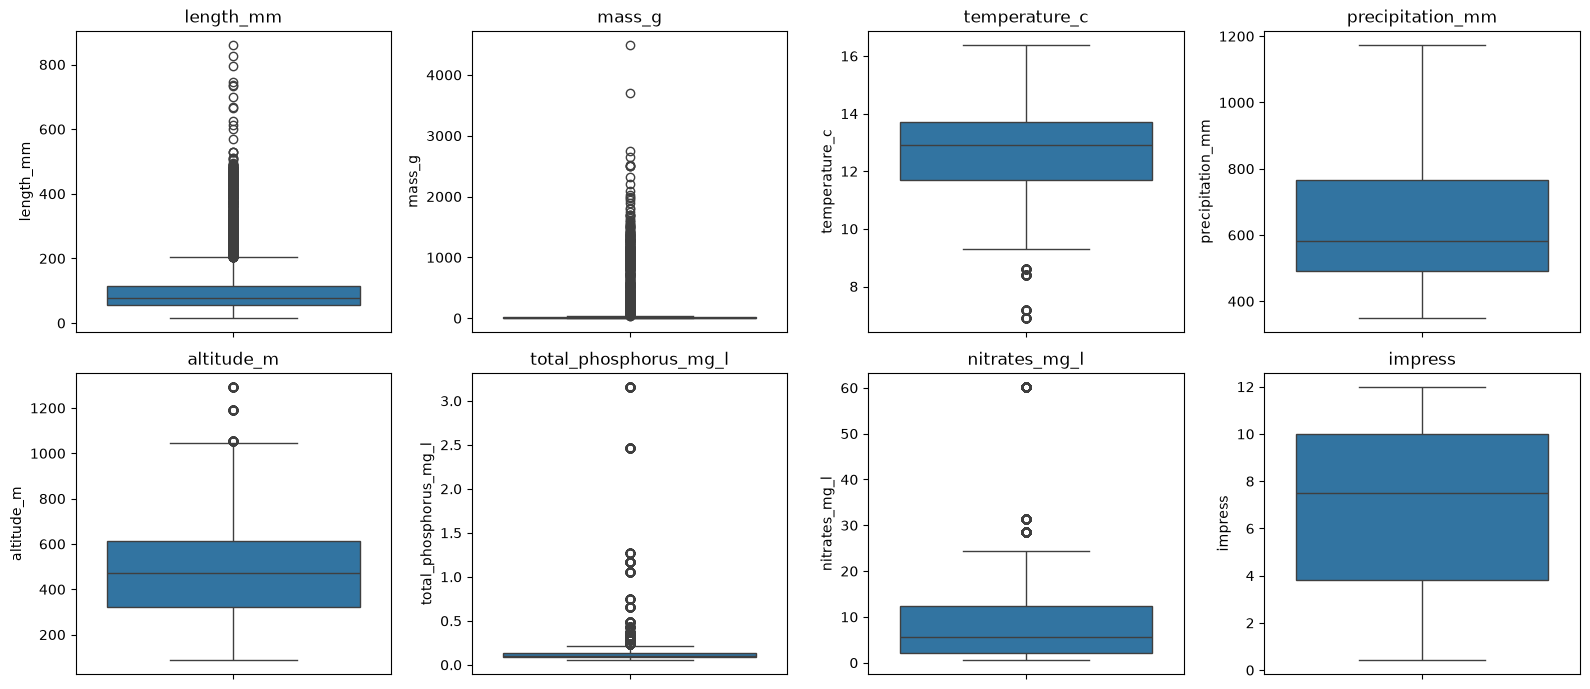

In [11]:
# Outliers with the IQR rule
for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} outliers")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [12]:
# Label checks: spaces and upper/lower case
for col in ["species", "Location"]:
    print(col)
    print("  unique values:", df[col].nunique())
    print("  unique after strip + lower:", df[col].str.strip().str.lower().nunique())
    print("  values with extra spaces:", (df[col] != df[col].str.strip()).sum())

df["species"].value_counts()

species
  unique values: 24
  unique after strip + lower: 24
  values with extra spaces: 0
Location
  unique values: 115
  unique after strip + lower: 115
  values with extra spaces: 236


species
Luciobarbus graellsii      2010
Phoxinus phoxinus          1957
Parachondrostoma miegii    1918
Salmo trutta               1475
Gobio lozanoi              1227
Barbus haasi               1125
Barbatula quignardi         681
Alburnus alburnus           387
Squalius laietanus          330
Achondrostoma arcasii       304
Salaria fluviatilis         198
Cobitis calderoni           193
Barbus meridionalis         175
Cyprinus carpio              91
Gambusia holbrooki           75
Lepomis gibbosus             50
Anguilla anguilla            28
Silurus glanis               27
Ameiurus melas               15
Carassius auratus             8
Micropterus salmoides         8
Oncorhynchus mykiss           3
Barbatula barbatula           2
Perca fluviatilis             1
Name: count, dtype: int64

**Findings**
* No missing values and no length or mass <= 0.
* 883 exact duplicates. The number of rows per site matches `Fish_number` for every site, so these are different fish with the same rounded length and mass. They are kept.
* The IQR outliers in length and mass are big fish (carp, barbel, trout), not errors. They are kept.
* Species names are clean. `Location` has trailing spaces in 236 rows.

## 3. Cleaning

In [13]:
# Fix labels (strip spaces)
before = len(df)
df["species"] = df["species"].str.strip()
df["Location"] = df["Location"].str.strip()
log.append(["fix_labels", before, len(df), "stripped spaces in species and Location"])

# Duplicates: kept (rows per site match Fish_number, so they are real fish)
log.append(["duplicates", len(df), len(df), "883 exact duplicates kept: they are different fish"])

# Impossible values
before = len(df)
df = df[(df["length_mm"] > 0) & (df["mass_g"] > 0)]
log.append(["impossible_values", before, len(df), "removed length or mass <= 0"])

# Missing values: drop rows with a missing value (no imputation to avoid leakage)
before = len(df)
df = df.dropna()
log.append(["missing_values", before, len(df), "dropped rows with missing values"])

# Outliers: kept
log.append(["outliers", len(df), len(df), "IQR outliers kept: real large fish"])

for row in log:
    print(row)

['load_and_merge', 12288, 12288, 'fish table joined to stream table on Code_ID']
['fix_labels', 12288, 12288, 'stripped spaces in species and Location']
['duplicates', 12288, 12288, '883 exact duplicates kept: they are different fish']
['impossible_values', 12288, 12288, 'removed length or mass <= 0']
['missing_values', 12288, 12288, 'dropped rows with missing values']
['outliers', 12288, 12288, 'IQR outliers kept: real large fish']


## 4. Species selection

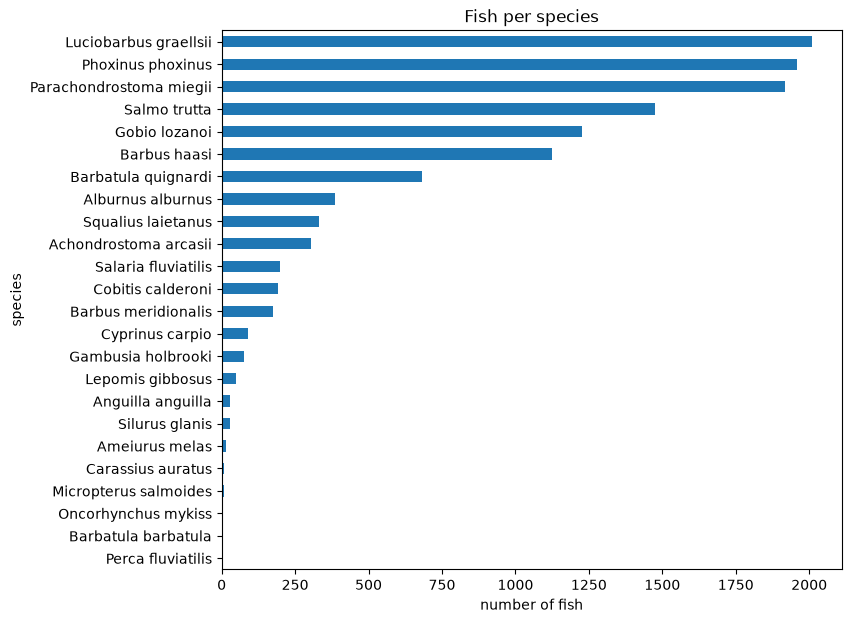

species
Luciobarbus graellsii      2010
Phoxinus phoxinus          1957
Parachondrostoma miegii    1918
Salmo trutta               1475
Gobio lozanoi              1227
Barbus haasi               1125
Barbatula quignardi         681
Alburnus alburnus           387
Squalius laietanus          330
Achondrostoma arcasii       304
Salaria fluviatilis         198
Cobitis calderoni           193
Barbus meridionalis         175
Cyprinus carpio              91
Gambusia holbrooki           75
Lepomis gibbosus             50
Anguilla anguilla            28
Silurus glanis               27
Ameiurus melas               15
Carassius auratus             8
Micropterus salmoides         8
Oncorhynchus mykiss           3
Barbatula barbatula           2
Perca fluviatilis             1
Name: count, dtype: int64

In [14]:
counts = df["species"].value_counts()
counts.plot(kind="barh", figsize=(8, 7))
plt.gca().invert_yaxis()
plt.xlabel("number of fish")
plt.title("Fish per species")
plt.show()

counts

We keep the **6** most abundant species. They all have more than 1,100 fish. After the 6th species (Barbus haasi, 1,125) the count drops to 681 (Barbatula quignardi), and the classes after that are much smaller.

In [15]:
top_species = counts.index[:6]

before = len(df)
df = df[df["species"].isin(top_species)].reset_index(drop=True)
log.append(["species_selection", before, len(df), "kept the 6 most abundant species"])

print("Kept species:", list(top_species))
print("Rows remaining:", len(df))

Kept species: ['Luciobarbus graellsii', 'Phoxinus phoxinus', 'Parachondrostoma miegii', 'Salmo trutta', 'Gobio lozanoi', 'Barbus haasi']
Rows remaining: 9712


## 5. Descriptive checks

species
Luciobarbus graellsii      2010
Phoxinus phoxinus          1957
Parachondrostoma miegii    1918
Salmo trutta               1475
Gobio lozanoi              1227
Barbus haasi               1125
Name: count, dtype: int64
Imbalance ratio (max/min): 1.79


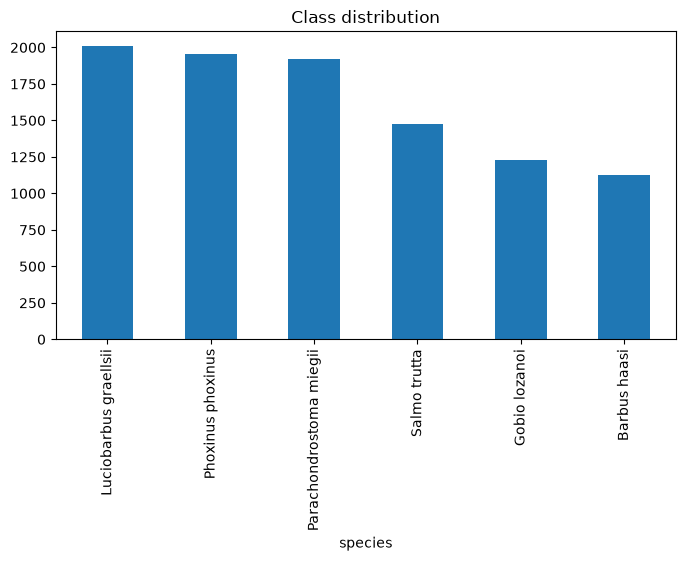

In [16]:
# Class distribution
class_counts = df["species"].value_counts()
print(class_counts)
print("Imbalance ratio (max/min):", round(class_counts.max() / class_counts.min(), 2))

class_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Class distribution")
plt.show()

Number of sites: 115

Fish per site:
count    115.000000
mean      84.452174
std       47.379254
min        4.000000
25%       52.000000
50%       70.000000
75%      106.000000
max      235.000000
dtype: float64

Species per site:
species
1    13
2    36
3    29
4    23
5    11
6     3
Name: count, dtype: int64


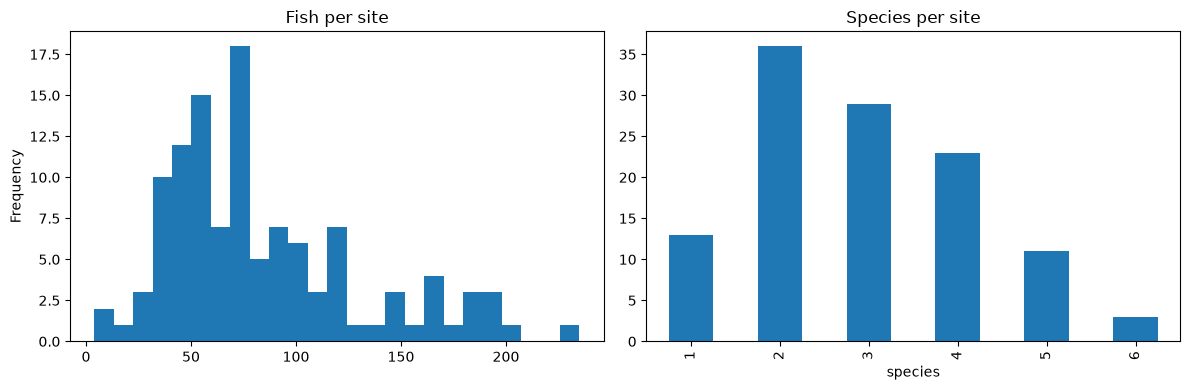

In [17]:
# Sites
print("Number of sites:", df["site"].nunique())

fish_per_site = df.groupby("site").size()
species_per_site = df.groupby("site")["species"].nunique()

print("\nFish per site:")
print(fish_per_site.describe())
print("\nSpecies per site:")
print(species_per_site.value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fish_per_site.plot(kind="hist", bins=25, ax=axes[0], title="Fish per site")
species_per_site.value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Species per site")
plt.tight_layout()
plt.show()

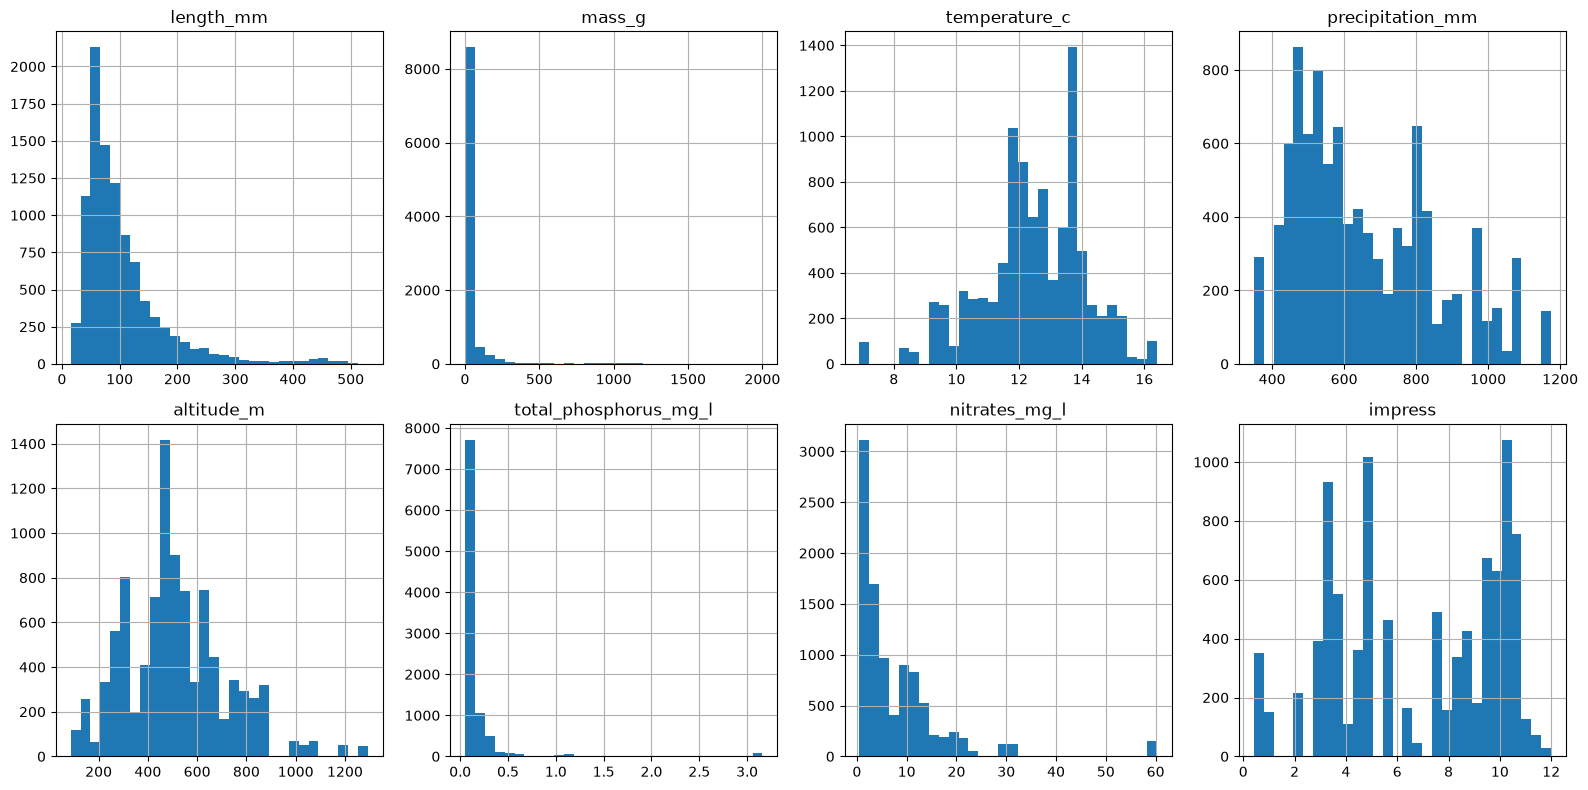

In [18]:
# Distributions of the 8 features
df[features].hist(bins=30, figsize=(16, 8), layout=(2, 4))
plt.tight_layout()
plt.show()

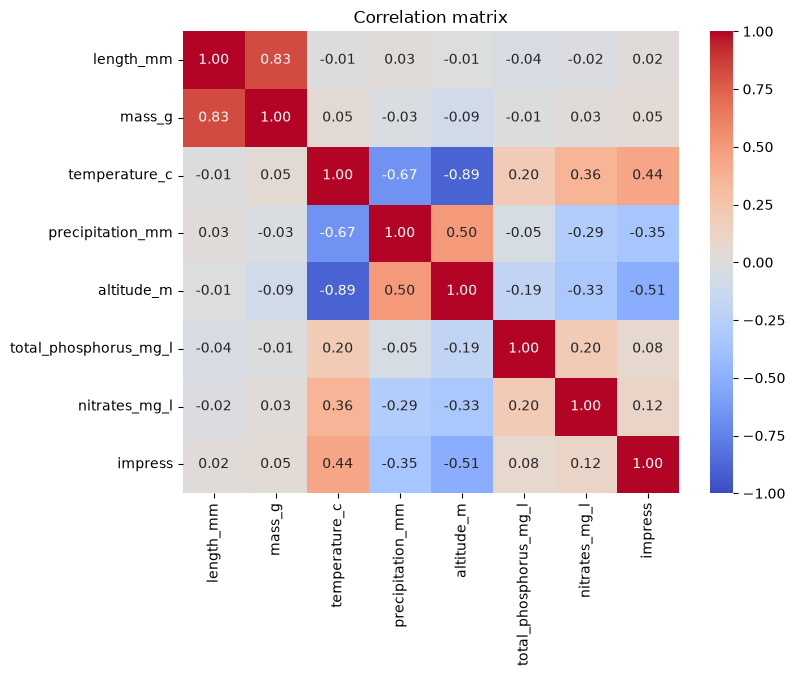

In [19]:
# Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

                          count        mean         std     min     25%  \
species                                                                   
Barbus haasi             1125.0  549.445893  212.335469  110.58  448.01   
Gobio lozanoi            1227.0  413.024857  154.090103  127.02  285.68   
Luciobarbus graellsii    2010.0  384.790910  141.061554  127.02  286.27   
Parachondrostoma miegii  1918.0  487.910125  161.235629  135.32  381.34   
Phoxinus phoxinus        1957.0  553.317098  170.331678   86.21  441.49   
Salmo trutta             1475.0  735.954664  219.686634  161.88  566.38   

                            50%     75%      max  
species                                           
Barbus haasi             518.95  655.67  1046.40  
Gobio lozanoi            435.55  517.48   774.79  
Luciobarbus graellsii    392.41  478.34   776.42  
Parachondrostoma miegii  472.43  556.97   884.30  
Phoxinus phoxinus        555.59  661.12  1052.38  
Salmo trutta             707.12  838.02  1

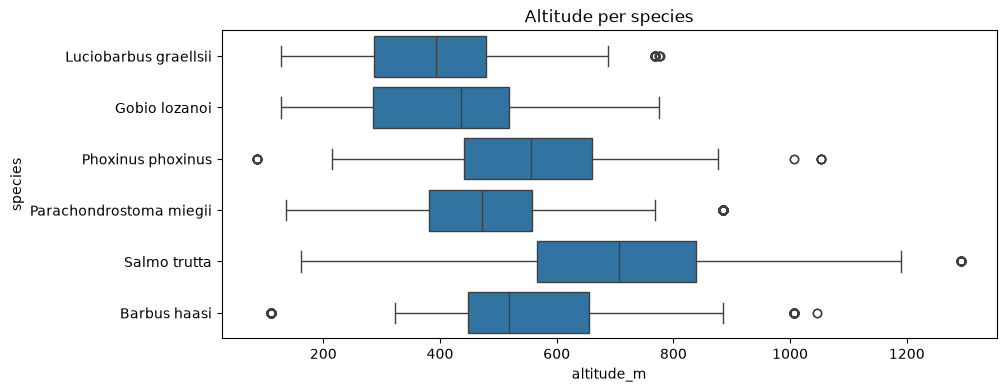

In [20]:
# Altitude range per species (important for the low vs high altitude test)
print(df.groupby("species")["altitude_m"].describe())

plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="altitude_m", y="species")
plt.title("Altitude per species")
plt.show()

## 6. Reference protocol: StratifiedGroupKFold

5 folds, grouped by site, so all fish from one site end up in the same fold.

In [21]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

df["fold"] = -1
for fold, (train_idx, test_idx) in enumerate(sgkf.split(df[features], df["species"], groups=df["site"])):
    df.loc[test_idx, "fold"] = fold

print("Fish per fold:")
print(df["fold"].value_counts().sort_index())
print("\nSites per fold:")
print(df.groupby("fold")["site"].nunique())

Fish per fold:
fold
0    1940
1    1939
2    1957
3    1932
4    1944
Name: count, dtype: int64

Sites per fold:
fold
0    25
1    22
2    24
3    22
4    22
Name: site, dtype: int64


In [22]:
# Class distribution per fold
pd.crosstab(df["fold"], df["species"])

species,Barbus haasi,Gobio lozanoi,Luciobarbus graellsii,Parachondrostoma miegii,Phoxinus phoxinus,Salmo trutta
fold,,,,,,
0,229,247,397,391,389,287
1,231,232,408,393,387,288
2,210,259,403,382,398,305
3,219,250,402,374,388,299
4,236,239,400,378,395,296


In [23]:
# Check that no site is in more than one fold
folds_per_site = df.groupby("site")["fold"].nunique()
print("Sites in more than one fold:", (folds_per_site > 1).sum())

Sites in more than one fold: 0


## 7. Save outputs

In [24]:
os.makedirs("../data/processed", exist_ok=True)

fish_clean = df[features + ["species", "site", "fold"]]
fish_clean.to_csv("../data/processed/fish_clean.csv", index=False)

cleaning_log = pd.DataFrame(log, columns=["step", "rows_before", "rows_after", "reason"])
cleaning_log.to_csv("../data/processed/cleaning_log.csv", index=False)

cleaning_log

,step,rows_before,rows_after,reason
0,load_and_merge,12288,12288,fish table joined to stream table on Code_ID
1,fix_labels,12288,12288,stripped spaces in species and Location
2,duplicates,12288,12288,883 exact duplicates kept: they are different ...
3,impossible_values,12288,12288,removed length or mass <= 0
4,missing_values,12288,12288,dropped rows with missing values
5,outliers,12288,12288,IQR outliers kept: real large fish
6,species_selection,12288,9712,kept the 6 most abundant species


## 8. Final summary

In [25]:
print("Final shape:", fish_clean.shape)
print("Features:", features)
print("\nKept species:")
print(fish_clean["species"].value_counts())

Final shape: (9712, 11)
Features: ['length_mm', 'mass_g', 'temperature_c', 'precipitation_mm', 'altitude_m', 'total_phosphorus_mg_l', 'nitrates_mg_l', 'impress']

Kept species:
species
Luciobarbus graellsii      2010
Phoxinus phoxinus          1957
Parachondrostoma miegii    1918
Salmo trutta               1475
Gobio lozanoi              1227
Barbus haasi               1125
Name: count, dtype: int64


**Warnings / limitations**
* 6 of the 8 inputs are site-level values: every fish from the same site has the same temperature, altitude, etc.
* Length and mass are almost perfectly correlated, and temperature is strongly correlated with altitude.
* Species live at different altitudes (Salmo trutta is mostly high up). A low vs high altitude split changes the class mix.
* The 883 duplicates and the IQR outliers were kept (see section 2).
* `TN_mg.l` may be total nitrogen rather than nitrates. Temperature is air temperature, not water temperature.